# Proyecto Final - Aprendizaje No Supervisado

## Análisis de patrones de operación y fallas mediante Clustering

En esta etapa del proyecto se aplicarán técnicas de aprendizaje no supervisado sobre los datos históricos de la flota.

El objetivo será identificar grupos de equipos con comportamientos similares a partir de sus características de uso, operación y antecedentes de fallas, sin utilizar una variable objetivo previamente definida.

Para ello se realizará una selección y preparación de variables, escalado de los datos, aplicación de un algoritmo de clustering y posterior análisis de los grupos obtenidos.

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

## 1. Carga del dataset procesado

Para el modelo no supervisado se utilizará el dataset de camiones previamente preparado durante las etapas de análisis exploratorio y feature engineering.

El objetivo será identificar grupos de observaciones con comportamientos similares a partir de las características de los equipos, su utilización y su historial de mantenimiento.

In [2]:
ruta = "../data/processed/dataset_registro_fallas_x_mes_CAMIONES_PROCESADO.csv"

df = pd.read_csv(
    ruta,
    sep=";",
    decimal=","
)

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (7874, 37)


,ID,EQUIPO,PERIODO,SUBUN,REQUIRIO_MANT,F_MOTOR,F_LUB_REFRIG,F_TRANSMISION,F_FRENOS,F_NEUMATICO,...,HS_MES,KM_MES,RAL_MES,HSOPE_MES,TIPO_CHASIS,CAPACIDAD_TN,RUTINA_MANT,CONSUMO_HS,CONSUMO_KM,ANTIGUEDAD
0,C3_2024-01,C3,2024-01,DTM-02,NO,0,0,0,0,0,...,105.0,74.0,93.0,0.0,DM800,58.0,PETROLERO,4.05,5.13,15.0
1,C5_2024-01,C5,2024-01,DTM-02,NO,0,0,0,0,0,...,21.0,29.0,11.0,0.0,CON GUINCHE,58.0,PETROLERO,17.15,3.29,44.0
2,C8_2024-01,C8,2024-01,DTM-02,NO,0,0,0,0,0,...,29.0,106.0,23.0,0.0,DM800,58.0,PETROLERO,5.11,0.67,16.0
3,C14_2024-01,C14,2024-01,DTM-02,NO,0,0,0,0,0,...,245.0,173.0,226.0,0.0,DM32,58.0,PETROLERO,3.11,3.11,17.0
4,C16_2024-01,C16,2024-01,DTM-02,NO,0,0,0,0,0,...,56.0,277.0,42.0,0.0,DM800,45.0,PETROLERO,6.16,0.81,13.0


## 2. Selección de variables para el clustering

Para realizar el clustering se seleccionarán inicialmente variables numéricas relacionadas con el uso del equipo, su antigüedad y su historial desde el último evento de mantenimiento.

No se utilizarán identificadores ni las variables que indican directamente la ocurrencia o el tipo de falla, ya que el objetivo es descubrir agrupaciones a partir de las características de los equipos y posteriormente analizar si los grupos encontrados presentan diferencias en su comportamiento de mantenimiento.

In [3]:
variables_cluster = [
    "HS_DESDE_ULT",
    "KM_DESDE_ULT",
    "RAL_DESDE_ULT",
    "DIAS_DESDE_ULT",
    "HS_MES",
    "KM_MES",
    "RAL_MES",
    "HSOPE_MES",
    "CAPACIDAD_TN",
    "CONSUMO_HS",
    "CONSUMO_KM",
    "ANTIGUEDAD"
]

df[variables_cluster].describe().round(2)

,HS_DESDE_ULT,KM_DESDE_ULT,RAL_DESDE_ULT,DIAS_DESDE_ULT,HS_MES,KM_MES,RAL_MES,HSOPE_MES,CAPACIDAD_TN,CONSUMO_HS,CONSUMO_KM,ANTIGUEDAD
count,7874.00,7874.00,7874.00,7874.00,7874.00,7874.00,7874.00,7874.00,7874.00,7874.00,7874.00,7843.00
mean,181.40,2754.72,98.30,38.67,162.04,2278.07,89.12,145.99,22.50,6.23,0.66,7.48
std,395.69,6639.41,211.42,72.08,164.97,2625.05,94.78,209.19,12.51,4.68,1.07,6.80
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-2.00
25%,0.00,0.00,0.00,0.00,2.00,0.00,1.00,0.00,16.50,0.41,0.06,3.00
50%,16.00,90.00,9.00,10.50,132.00,1380.00,70.00,0.00,24.00,6.60,0.52,7.00
75%,204.00,2622.50,107.00,44.00,254.00,3786.25,136.00,262.00,24.00,9.04,0.63,10.00
max,5779.00,82439.00,2608.00,709.00,847.00,18352.00,531.00,1182.00,58.00,20.82,8.29,46.00


### Revisión de calidad de las variables seleccionadas

Antes del escalado se revisan posibles valores faltantes o inconsistentes en las variables seleccionadas, ya que estos pueden afectar el cálculo de distancias utilizado por los algoritmos de clustering.

In [4]:
print("Valores faltantes:")
print(df[variables_cluster].isna().sum())

print("\nAntigüedad negativa:")
display(
    df.loc[
        df["ANTIGUEDAD"] < 0,
        ["EQUIPO", "PERIODO", "ANTIGUEDAD"]
    ]
)


Valores faltantes:
HS_DESDE_ULT       0
KM_DESDE_ULT       0
RAL_DESDE_ULT      0
DIAS_DESDE_ULT     0
HS_MES             0
KM_MES             0
RAL_MES            0
HSOPE_MES          0
CAPACIDAD_TN       0
CONSUMO_HS         0
CONSUMO_KM         0
ANTIGUEDAD        31
dtype: int64

Antigüedad negativa:


,EQUIPO,PERIODO,ANTIGUEDAD
23,C45,2024-01,-2.0
205,N355,2024-01,-1.0
206,N356,2024-01,-1.0
207,N357,2024-01,-1.0
208,N358,2024-01,-1.0
...,...,...,...
6080,N395,2025-12,-1.0
6081,N396,2025-12,-1.0
6082,N397,2025-12,-1.0
6089,D11,2025-12,-1.0


### Tratamiento de valores faltantes

La variable `ANTIGUEDAD` presenta una pequeña cantidad de valores faltantes, mientras que el resto de las variables seleccionadas se encuentran completas.

Dado que representan una proporción muy pequeña del dataset, se decidió excluir estos registros del análisis de clustering en lugar de imputar valores artificiales.

In [5]:
X_cluster = df[variables_cluster].dropna().copy()

print("Registros originales:", len(df))
print("Registros para clustering:", len(X_cluster))
print("Registros excluidos:", len(df) - len(X_cluster))

Registros originales: 7874
Registros para clustering: 7843
Registros excluidos: 31


## 3. Escalado de las variables

K-Means agrupa las observaciones en función de la distancia entre ellas. Como las variables seleccionadas presentan escalas muy diferentes, es necesario estandarizarlas para evitar que aquellas con valores numéricamente mayores tengan una influencia desproporcionada sobre la formación de los clusters.

Para ello se utilizará StandardScaler.

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_cluster)

print("Dimensiones:", X_scaled.shape)

Dimensiones: (7843, 12)


## 4. Elección de la cantidad de clusters

K-Means requiere definir previamente la cantidad de grupos que se desea formar.

Como en este caso no conocemos de antemano cuántos grupos naturales pueden existir en los datos, se evaluarán distintas cantidades de clusters para seleccionar una configuración adecuada bajo un criterio objetivo.

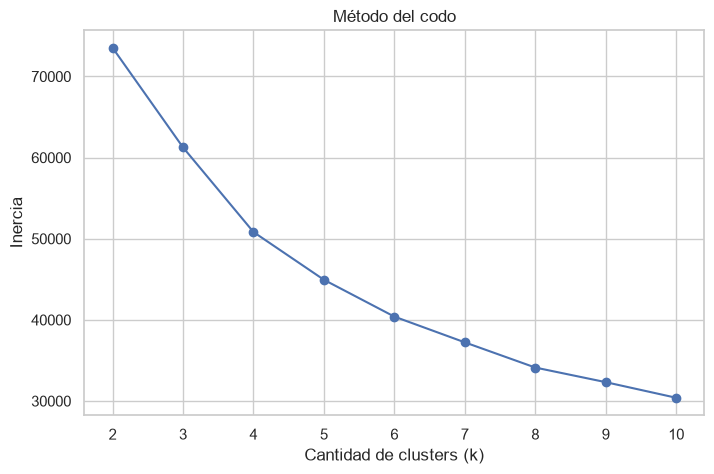

In [7]:
inercias = []

rango_k = range(2, 11)

for k in rango_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker="o")

plt.xlabel("Cantidad de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")

plt.show()

### Evaluación mediante coeficiente de silueta

El método del codo muestra una reducción progresiva de la inercia, pero no presenta un punto de quiebre completamente definido.

Por este motivo, la elección de la cantidad de clusters se complementará con el coeficiente de silueta, que permite evaluar simultáneamente la cohesión interna de los grupos y su separación respecto de los demás clusters.

In [8]:
from sklearn.metrics import silhouette_score

resultados_k = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_scaled)

    silueta = silhouette_score(
        X_scaled,
        etiquetas,
        sample_size=3000,
        random_state=42
    )

    resultados_k.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": silueta
    })

resultados_k = pd.DataFrame(resultados_k)

display(resultados_k.round(3))

,k,inercia,silueta
0,2,73536.126,0.265
1,3,61257.255,0.241
2,4,50827.030,0.277
3,5,44941.832,0.239
4,6,40401.054,0.255
5,7,37229.720,0.236
6,8,34126.215,0.244
7,9,32325.320,0.247
8,10,30401.919,0.250


### Selección inicial de la cantidad de clusters

El método del codo mostró una disminución progresiva de la inercia, con un cambio de pendiente alrededor de 4 y 5 clusters, aunque sin presentar un punto de quiebre completamente definido.

Para complementar este criterio se calculó el coeficiente de silueta para valores de k entre 2 y 10.

La mayor silueta se obtuvo con **k = 4 (0.277)**. Por este motivo se seleccionan inicialmente **4 clusters**.

El valor de silueta obtenido indica que la separación entre los grupos no es especialmente alta, por lo que posteriormente se revisará la configuración del modelo y las variables utilizadas para evaluar posibles mejoras.

## 5. Entrenamiento inicial del modelo K-Means

A partir de los criterios anteriores se entrenará un modelo K-Means con 4 clusters.

El objetivo inicial será analizar cómo se distribuyen las observaciones entre los grupos encontrados. Posteriormente se estudiarán las características de cada cluster para determinar qué patrones representan.

In [9]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

# Guardamos el cluster respetando los índices originales
df_cluster = df.loc[X_cluster.index].copy()
df_cluster["CLUSTER"] = clusters

print("Cantidad de registros por cluster:")
print(df_cluster["CLUSTER"].value_counts().sort_index())

print("\nPorcentaje por cluster:")
print(
    (df_cluster["CLUSTER"].value_counts(normalize=True)
     .sort_index() * 100)
     .round(2)
)

Cantidad de registros por cluster:
CLUSTER
0     372
1    3258
2    3799
3     414
Name: count, dtype: int64

Porcentaje por cluster:
CLUSTER
0     4.74
1    41.54
2    48.44
3     5.28
Name: proportion, dtype: float64


## 6. Caracterización de los clusters

Una vez obtenidos los grupos, se analizarán los valores promedio de las variables utilizadas en el modelo para identificar las principales características que diferencian a cada cluster.

Esto permitirá interpretar los grupos encontrados y determinar si representan perfiles de operación relevantes dentro de la flota.

In [10]:
perfil_clusters = (
    df_cluster
    .groupby("CLUSTER")[variables_cluster]
    .mean()
    .round(2)
)

perfil_clusters

,HS_DESDE_ULT,KM_DESDE_ULT,RAL_DESDE_ULT,DIAS_DESDE_ULT,HS_MES,KM_MES,RAL_MES,HSOPE_MES,CAPACIDAD_TN,CONSUMO_HS,CONSUMO_KM,ANTIGUEDAD
CLUSTER,,,,,,,,,,,,
0,69.14,61.94,61.10,30.42,84.96,144.63,73.90,96.99,54.08,6.61,4.59,17.76
1,173.25,2589.33,94.27,25.05,299.17,4342.41,160.53,258.55,24.30,8.41,0.56,6.80
2,59.60,907.58,32.34,37.66,37.40,490.51,21.62,27.21,17.51,4.25,0.33,7.42
3,1474.79,23629.74,773.68,164.46,299.95,4516.30,159.93,392.57,23.00,6.92,0.42,4.18


In [11]:
resumen_equipos = (
    df_cluster
    .groupby("CLUSTER")
    .agg(
        REGISTROS=("EQUIPO", "size"),
        EQUIPOS_UNICOS=("EQUIPO", "nunique")
    )
)

resumen_equipos

,REGISTROS,EQUIPOS_UNICOS
CLUSTER,,
0,372,12
1,3258,207
2,3799,235
3,414,108


### Relación de los clusters con los eventos de mantenimiento

La variable `REQUIRIO_MANT` no fue utilizada para entrenar el modelo de clustering.

Una vez formados los grupos, se utilizará esta información únicamente para interpretar los clusters y analizar si los perfiles encontrados presentan diferencias en la frecuencia de eventos de mantenimiento.

In [12]:
tasa_mantenimiento = (
    df_cluster
    .assign(MANT=lambda x: (x["REQUIRIO_MANT"] == "SI").astype(int))
    .groupby("CLUSTER")
    .agg(
        REGISTROS=("MANT", "size"),
        MANTENIMIENTOS=("MANT", "sum"),
        TASA_MANT=("MANT", "mean")
    )
)

tasa_mantenimiento["TASA_MANT"] = (
    tasa_mantenimiento["TASA_MANT"] * 100
).round(2)

tasa_mantenimiento

,REGISTROS,MANTENIMIENTOS,TASA_MANT
CLUSTER,,,
0,372,157,42.20
1,3258,1562,47.94
2,3799,839,22.08
3,414,137,33.09


### Interpretación respecto de los eventos de mantenimiento

Los clusters fueron generados sin utilizar la variable `REQUIRIO_MANT`. Posteriormente, esta variable se utilizó únicamente para analizar las características de los grupos encontrados.

Se observaron diferencias importantes en la frecuencia de mantenimiento entre los clusters. El Cluster 1 presentó la mayor tasa de mantenimiento (47,94%), mientras que el Cluster 2 presentó la menor (22,08%).

Estos dos grupos también mostraron diferencias claras en sus niveles de utilización mensual, ya que el Cluster 1 presenta una actividad considerablemente mayor que el Cluster 2.

El resultado sugiere que el clustering logró identificar perfiles operativos diferentes dentro de la flota que también presentan comportamientos distintos respecto del mantenimiento.

Sin embargo, esta asociación no implica causalidad ni convierte al clustering en un modelo predictivo, sino que permite caracterizar y explorar diferentes perfiles presentes en los datos.

## Conclusión del primer modelo de clustering

El modelo K-Means permitió identificar **cuatro perfiles claramente diferenciados dentro de la operación de la flota**:

- **Cluster 0 - Equipos pesados y específicos:** representa un grupo pequeño y muy particular de la flota. Está compuesto por equipos de gran capacidad (54 tn en promedio), mayor antigüedad y bajo kilometraje mensual. Presenta una tasa de mantenimiento del **42,20%**.

- **Cluster 1 - Alta utilización:** concentra equipos con una actividad mensual elevada, con aproximadamente 299 horas y 4.342 km mensuales. Es el grupo con la **mayor tasa de mantenimiento, 47,94%**, lo que lo convierte en uno de los perfiles más relevantes desde el punto de vista operativo.

- **Cluster 2 - Baja utilización:** representa prácticamente la mitad de las observaciones y se caracteriza por niveles considerablemente menores de actividad, con aproximadamente 37 horas y 491 km mensuales. También presenta la **menor tasa de mantenimiento, 22,08%**.

- **Cluster 3 - Alta utilización acumulada desde el último evento:** agrupa observaciones con niveles elevados de actividad mensual, pero se diferencia principalmente por el uso acumulado desde el último evento: aproximadamente 1.475 horas, 23.630 km y 164 días. Su tasa de mantenimiento es del **33,09%**.

### Hallazgo principal

El resultado más importante es que el algoritmo logró separar la flota en perfiles operativos con comportamientos de mantenimiento muy diferentes **sin utilizar `REQUIRIO_MANT` para construir los clusters**.

La comparación entre los clusters 1 y 2 es especialmente clara: el grupo de alta utilización presenta una tasa de mantenimiento del **47,94%**, mientras que el grupo de baja utilización alcanza solamente el **22,08%**.

Esto sugiere que el nivel y el tipo de utilización de los equipos constituyen características importantes para segmentar la flota y que el clustering puede ser utilizado como herramienta exploratoria para identificar perfiles operativos con diferente exposición al mantenimiento.

También se observa que una mayor acumulación desde el último evento no implica necesariamente una mayor tasa de mantenimiento, ya que el Cluster 3, pese a presentar valores acumulados muy superiores, alcanza una tasa del 33,09%.

En conclusión, el clustering no permite predecir directamente una falla, pero sí aporta una nueva perspectiva al proyecto: **permite pasar de analizar la flota como un único conjunto a reconocer distintos perfiles operativos con comportamientos de mantenimiento diferenciados.**

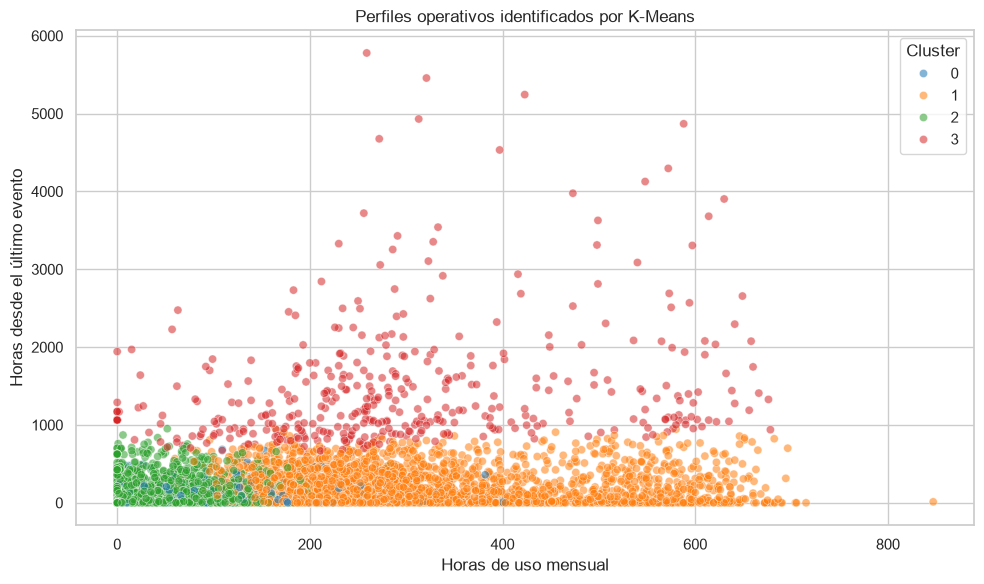

In [18]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_cluster,
    x="HS_MES",
    y="HS_DESDE_ULT",
    hue="CLUSTER",
    palette="tab10",
    alpha=0.55,
    s=35
)

plt.xlabel("Horas de uso mensual")
plt.ylabel("Horas desde el último evento")
plt.title("Perfiles operativos identificados por K-Means")

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

### Visualización de los perfiles operativos

Para representar visualmente el modelo inicial de cuatro clusters se seleccionan las variables `HS_MES` y `HS_DESDE_ULT`.

Estas variables permiten comparar el nivel de utilización mensual de cada observación con las horas acumuladas desde el último evento de mantenimiento, dos características relevantes para interpretar los perfiles encontrados.

## 7. Revisión y mejora del modelo

El modelo inicial permitió obtener clusters interpretables, aunque el coeficiente de silueta obtenido (0.277) indica una separación moderada entre los grupos.

Como posible mejora se revisará la selección de variables. El modelo inicial contiene varias medidas relacionadas con fenómenos similares, principalmente utilización mensual y utilización acumulada desde el último evento.

Se evaluará una configuración más simple, reduciendo la cantidad de variables y conservando indicadores representativos del nivel de utilización, acumulación desde el último mantenimiento y características del equipo.

El objetivo es determinar si una representación menos redundante permite obtener clusters mejor separados.

In [13]:
variables_mejora = [
    "HS_MES",
    "KM_MES",
    "HS_DESDE_ULT",
    "KM_DESDE_ULT",
    "DIAS_DESDE_ULT",
    "CAPACIDAD_TN",
    "ANTIGUEDAD"
]

df[variables_mejora].corr().round(2)

,HS_MES,KM_MES,HS_DESDE_ULT,KM_DESDE_ULT,DIAS_DESDE_ULT,CAPACIDAD_TN,ANTIGUEDAD
HS_MES,1.00,0.80,0.30,0.23,-0.05,0.15,-0.12
KM_MES,0.80,1.00,0.27,0.31,-0.02,0.05,-0.16
HS_DESDE_ULT,0.30,0.27,1.00,0.89,0.50,0.05,-0.11
KM_DESDE_ULT,0.23,0.31,0.89,1.00,0.48,0.02,-0.12
DIAS_DESDE_ULT,-0.05,-0.02,0.50,0.48,1.00,0.03,0.16
CAPACIDAD_TN,0.15,0.05,0.05,0.02,0.03,1.00,0.24
ANTIGUEDAD,-0.12,-0.16,-0.11,-0.12,0.16,0.24,1.00


### Reducción de variables correlacionadas

El análisis de correlación mostró una relación elevada entre `HS_MES` y `KM_MES` (0.80), y especialmente entre `HS_DESDE_ULT` y `KM_DESDE_ULT` (0.89).

Debido a que K-Means utiliza distancias para formar los grupos, incluir múltiples variables que representan fenómenos muy similares puede aumentar innecesariamente el peso de determinadas características.

Por este motivo se decidió evaluar una segunda configuración más simple, conservando una variable representativa del nivel de utilización mensual y otra del uso acumulado desde el último evento.

La nueva configuración utilizará `HS_MES`, `HS_DESDE_ULT`, `DIAS_DESDE_ULT`, `CAPACIDAD_TN` y `ANTIGUEDAD`.

In [14]:
variables_mejora = [
    "HS_MES",
    "HS_DESDE_ULT",
    "DIAS_DESDE_ULT",
    "CAPACIDAD_TN",
    "ANTIGUEDAD"
]

X_mejora = df[variables_mejora].dropna().copy()

scaler_mejora = StandardScaler()
X_mejora_scaled = scaler_mejora.fit_transform(X_mejora)

resultados_mejora = []

for k in range(2, 11):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X_mejora_scaled)

    silueta = silhouette_score(
        X_mejora_scaled,
        etiquetas,
        sample_size=3000,
        random_state=42
    )

    resultados_mejora.append({
        "k": k,
        "silueta": silueta
    })

pd.DataFrame(resultados_mejora).round(3)

,k,silueta
0,2,0.451
1,3,0.230
2,4,0.269
3,5,0.281
4,6,0.314
5,7,0.335
6,8,0.343
7,9,0.311
8,10,0.331


### Resultado de la mejora

La reducción de variables produjo una mejora importante en la separación de los clusters.

El modelo inicial, construido con 12 variables, alcanzó un coeficiente de silueta máximo de **0.277 con 4 clusters**.

Luego de reducir variables altamente correlacionadas y conservar cinco características representativas, la mejor configuración alcanzó una silueta de **0.451 con 2 clusters**.

Esto indica que una representación más simple de los datos permite identificar grupos considerablemente más definidos.

Por este motivo se selecciona como modelo final la configuración de **K-Means con 2 clusters**, utilizando `HS_MES`, `HS_DESDE_ULT`, `DIAS_DESDE_ULT`, `CAPACIDAD_TN` y `ANTIGUEDAD`.

## 8. Modelo final mejorado

Luego de revisar las variables utilizadas, se seleccionó una configuración reducida de cinco características.

La evaluación mediante el coeficiente de silueta mostró que la mejor separación se obtiene con 2 clusters, alcanzando un valor de 0.451 frente al 0.277 del modelo inicial.

A continuación se entrenará el modelo final y se analizarán las características de los dos grupos encontrados.

In [15]:
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters_final = kmeans_final.fit_predict(X_mejora_scaled)

df_final = df.loc[X_mejora.index].copy()
df_final["CLUSTER_FINAL"] = clusters_final

print("Distribución de clusters:")
print(df_final["CLUSTER_FINAL"].value_counts().sort_index())

print("\nPorcentaje:")
print(
    (df_final["CLUSTER_FINAL"]
     .value_counts(normalize=True)
     .sort_index() * 100)
    .round(2)
)

print("\nPerfil promedio:")
display(
    df_final
    .groupby("CLUSTER_FINAL")[variables_mejora]
    .mean()
    .round(2)
)

Distribución de clusters:
CLUSTER_FINAL
0     801
1    7042
Name: count, dtype: int64

Porcentaje:
CLUSTER_FINAL
0    10.21
1    89.79
Name: proportion, dtype: float64

Perfil promedio:


,HS_MES,HS_DESDE_ULT,DIAS_DESDE_ULT,CAPACIDAD_TN,ANTIGUEDAD
CLUSTER_FINAL,,,,,
0,195.87,931.85,200.79,22.30,8.08
1,158.43,96.67,20.34,22.36,7.41


In [16]:
comparacion_mant = (
    df_final
    .assign(MANT=lambda x: (x["REQUIRIO_MANT"] == "SI").astype(int))
    .groupby("CLUSTER_FINAL")
    .agg(
        REGISTROS=("MANT", "size"),
        MANTENIMIENTOS=("MANT", "sum"),
        TASA_MANT=("MANT", "mean")
    )
)

comparacion_mant["TASA_MANT"] = (
    comparacion_mant["TASA_MANT"] * 100
).round(2)

comparacion_mant

,REGISTROS,MANTENIMIENTOS,TASA_MANT
CLUSTER_FINAL,,,
0,801,216,26.97
1,7042,2479,35.20


## Conclusión final

El análisis comenzó con un modelo K-Means basado en 12 variables, donde se identificaron cuatro perfiles operativos diferentes. Esta configuración obtuvo un coeficiente de silueta de 0.277 y permitió distinguir grupos asociados principalmente con baja utilización, alta utilización, equipos de características particulares y altos niveles de uso acumulado.

Posteriormente se revisó la selección de variables y se detectaron correlaciones elevadas entre algunas medidas de utilización. Se construyó una segunda versión reduciendo el modelo a cinco variables representativas.

La nueva configuración alcanzó una silueta de **0.451 con 2 clusters**, mejorando considerablemente la separación matemática respecto del modelo inicial.

El modelo mejorado diferenció principalmente dos estados operativos: un grupo minoritario con elevados niveles de horas y días acumulados desde el último evento y un grupo mayoritario con valores considerablemente menores.

Al comparar posteriormente los clusters con `REQUIRIO_MANT`, variable que no fue utilizada durante el entrenamiento, se observó una tasa de mantenimiento del **26,97%** en el grupo con mayor acumulación y del **35,20%** en el grupo mayoritario.

Este resultado muestra que una mayor acumulación de horas o días desde el último evento no implica necesariamente una mayor frecuencia de mantenimiento.

En conclusión, la reducción de variables permitió obtener clusters matemáticamente más definidos, aunque la configuración inicial de cuatro clusters proporcionó una segmentación operativa más detallada.

Por lo tanto, ambos análisis

## Visualización del modelo final

Para visualizar los grupos encontrados se seleccionan `HS_DESDE_ULT` y `DIAS_DESDE_ULT`, dos de las variables que muestran una mayor diferencia entre los perfiles obtenidos.

El gráfico permite observar visualmente cómo K-Means separó las observaciones de acuerdo con su nivel de acumulación desde el último evento.

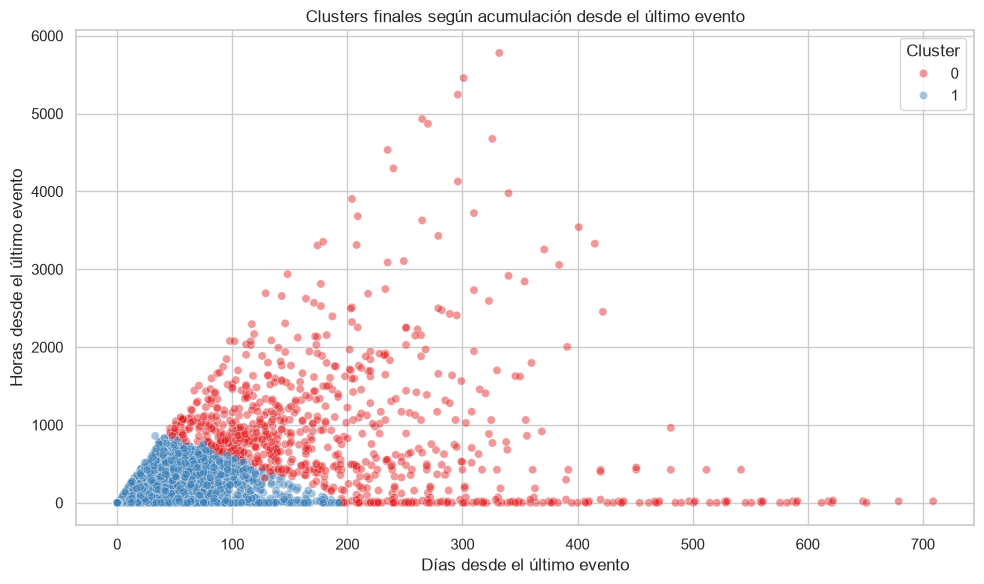

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_final,
    x="DIAS_DESDE_ULT",
    y="HS_DESDE_ULT",
    hue="CLUSTER_FINAL",
    palette="Set1",
    alpha=0.45,
    s=35
)

plt.xlabel("Días desde el último evento")
plt.ylabel("Horas desde el último evento")
plt.title("Clusters finales según acumulación desde el último evento")

plt.legend(title="Cluster")
plt.tight_layout()
plt.show()